# Feature Selection for Classification and Regression

Lab Assignment 8 - applying three feature selection approaches (SelectKBest, RFE and tree-based selection) to the Iris dataset for classification and the Boston Housing dataset for regression, and comparing how the models perform with the selected features.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, f_regression, RFE, SelectFromModel
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

## 1. Load the datasets

Iris comes with sklearn. The Boston Housing dataset was removed from newer versions of sklearn, so it is loaded from a CSV instead. Target column is medv (median house value in $1000s).

In [2]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
iris_df['species'] = iris.target
iris_df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
boston_df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv')
boston_df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [4]:
print("Iris:", iris_df.shape)
print("Boston:", boston_df.shape)

Iris: (150, 5)
Boston: (506, 14)


## 2. Preprocessing

Checking for missing values and categorical columns. Iris species is already label encoded (0, 1, 2) and in Boston the only categorical-like column is chas, which is already 0/1. Any missing values are filled with the column median just in case.

In [5]:
print("Iris missing values:", iris_df.isnull().sum().sum())
print("Boston missing values:", boston_df.isnull().sum().sum())

Iris missing values: 0
Boston missing values: 0


In [6]:
boston_df = boston_df.fillna(boston_df.median())
boston_df.dtypes

,0
crim,float64
zn,float64
indus,float64
chas,int64
nox,float64
rm,float64
age,float64
dis,float64
rad,int64
tax,int64


## 3. Features and target, train/test split

70/30 split for both datasets. Features are standardized using the training set only. They are kept as DataFrames so the selected columns can be picked out by name.

In [7]:
X_iris = iris_df.drop('species', axis=1)
y_iris = iris_df['species']

Xi_train, Xi_test, yi_train, yi_test = train_test_split(X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

scaler = StandardScaler()
Xi_train = pd.DataFrame(scaler.fit_transform(Xi_train), columns=X_iris.columns)
Xi_test = pd.DataFrame(scaler.transform(Xi_test), columns=X_iris.columns)

In [8]:
X_boston = boston_df.drop('medv', axis=1)
y_boston = boston_df['medv']

Xb_train, Xb_test, yb_train, yb_test = train_test_split(X_boston, y_boston, test_size=0.3, random_state=42)

scaler = StandardScaler()
Xb_train = pd.DataFrame(scaler.fit_transform(Xb_train), columns=X_boston.columns)
Xb_test = pd.DataFrame(scaler.transform(Xb_test), columns=X_boston.columns)

## 4. Feature selection - Iris (classification)

Three approaches:
1. **SelectKBest (ANOVA F-test)** - filter method, scores each feature on its own against the target.
2. **RFE** - wrapper method, repeatedly fits a Logistic Regression and drops the weakest feature.
3. **Tree-based (SelectFromModel)** - embedded method, keeps features whose Random Forest importance is above the mean.

Iris only has 4 features, so the first two methods are set to keep 2.

In [9]:
iris_features = {'All features': list(X_iris.columns)}

kbest = SelectKBest(score_func=f_classif, k=2)
kbest.fit(Xi_train, yi_train)
print(pd.Series(kbest.scores_, index=X_iris.columns).sort_values(ascending=False))
iris_features['SelectKBest'] = list(X_iris.columns[kbest.get_support()])

petal length (cm)    814.733158
petal width (cm)     791.349745
sepal length (cm)     95.760855
sepal width (cm)      33.059484
dtype: float64


In [10]:
rfe = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=2)
rfe.fit(Xi_train, yi_train)
iris_features['RFE'] = list(X_iris.columns[rfe.support_])

In [11]:
sfm = SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=42))
sfm.fit(Xi_train, yi_train)
iris_features['Tree-based'] = list(X_iris.columns[sfm.get_support()])

iris_features

{'All features': ['sepal length (cm)',
  'sepal width (cm)',
  'petal length (cm)',
  'petal width (cm)'],
 'SelectKBest': ['petal length (cm)', 'petal width (cm)'],
 'RFE': ['petal length (cm)', 'petal width (cm)'],
 'Tree-based': ['petal length (cm)', 'petal width (cm)']}

Training a Logistic Regression on each subset of features and checking accuracy on the test set.

In [12]:
iris_results = []
for method, feats in iris_features.items():
    model = LogisticRegression(max_iter=1000)
    model.fit(Xi_train[feats], yi_train)
    acc = accuracy_score(yi_test, model.predict(Xi_test[feats]))
    iris_results.append({'Method': method, 'Num Features': len(feats), 'Features': ', '.join(feats), 'Accuracy': acc})

iris_results = pd.DataFrame(iris_results)
iris_results

,Method,Num Features,Features,Accuracy
0,All features,4,"sepal length (cm), sepal width (cm), petal len...",0.911111
1,SelectKBest,2,"petal length (cm), petal width (cm)",0.911111
2,RFE,2,"petal length (cm), petal width (cm)",0.911111
3,Tree-based,2,"petal length (cm), petal width (cm)",0.911111


## 5. Feature selection - Boston Housing (regression)

Same three approaches, but with the regression versions: f_regression for SelectKBest, Linear Regression inside RFE and a Random Forest Regressor for the tree-based method. Boston has 13 features, so the first two methods keep 6.

In [13]:
boston_features = {'All features': list(X_boston.columns)}

kbest = SelectKBest(score_func=f_regression, k=6)
kbest.fit(Xb_train, yb_train)
print(pd.Series(kbest.scores_, index=X_boston.columns).sort_values(ascending=False))
boston_features['SelectKBest'] = list(X_boston.columns[kbest.get_support()])

lstat      444.683492
rm         335.351367
ptratio    112.476791
indus       94.249230
tax         90.534912
nox         69.752049
rad         61.144268
crim        59.572821
age         49.301500
zn          42.878752
b           41.568465
dis         21.767012
chas        19.032608
dtype: float64


In [14]:
rfe = RFE(estimator=LinearRegression(), n_features_to_select=6)
rfe.fit(Xb_train, yb_train)
boston_features['RFE'] = list(X_boston.columns[rfe.support_])

In [15]:
rf = RandomForestRegressor(n_estimators=200, random_state=42)
sfm = SelectFromModel(rf)
sfm.fit(Xb_train, yb_train)
boston_features['Tree-based'] = list(X_boston.columns[sfm.get_support()])

boston_features

{'All features': ['crim',
  'zn',
  'indus',
  'chas',
  'nox',
  'rm',
  'age',
  'dis',
  'rad',
  'tax',
  'ptratio',
  'b',
  'lstat'],
 'SelectKBest': ['indus', 'nox', 'rm', 'tax', 'ptratio', 'lstat'],
 'RFE': ['crim', 'nox', 'rm', 'dis', 'ptratio', 'lstat'],
 'Tree-based': ['rm', 'lstat']}

Training a Linear Regression on each subset and evaluating with MSE and R².

In [16]:
boston_results = []
for method, feats in boston_features.items():
    model = LinearRegression()
    model.fit(Xb_train[feats], yb_train)
    y_pred = model.predict(Xb_test[feats])
    boston_results.append({
        'Method': method,
        'Num Features': len(feats),
        'Features': ', '.join(feats),
        'MSE': mean_squared_error(yb_test, y_pred),
        'R2': r2_score(yb_test, y_pred)
    })

boston_results = pd.DataFrame(boston_results)
boston_results.round(4)

,Method,Num Features,Features,MSE,R2
0,All features,13,"crim, zn, indus, chas, nox, rm, age, dis, rad,...",21.5174,0.7112
1,SelectKBest,6,"indus, nox, rm, tax, ptratio, lstat",25.9834,0.6513
2,RFE,6,"crim, nox, rm, dis, ptratio, lstat",23.2131,0.6885
3,Tree-based,2,"rm, lstat",29.8163,0.5999


## 6. Comparison

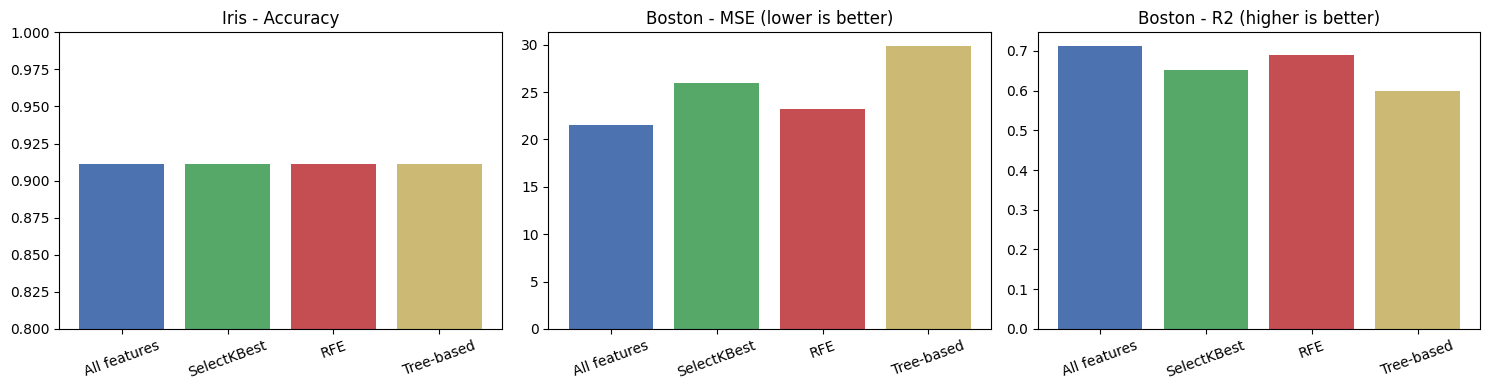

In [17]:
colors = ['#4c72b0', '#55a868', '#c44e52', '#ccb974']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].bar(iris_results['Method'], iris_results['Accuracy'], color=colors)
axes[0].set_title('Iris - Accuracy')
axes[0].set_ylim(0.8, 1.0)

axes[1].bar(boston_results['Method'], boston_results['MSE'], color=colors)
axes[1].set_title('Boston - MSE (lower is better)')

axes[2].bar(boston_results['Method'], boston_results['R2'], color=colors)
axes[2].set_title('Boston - R2 (higher is better)')

for ax in axes:
    ax.tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

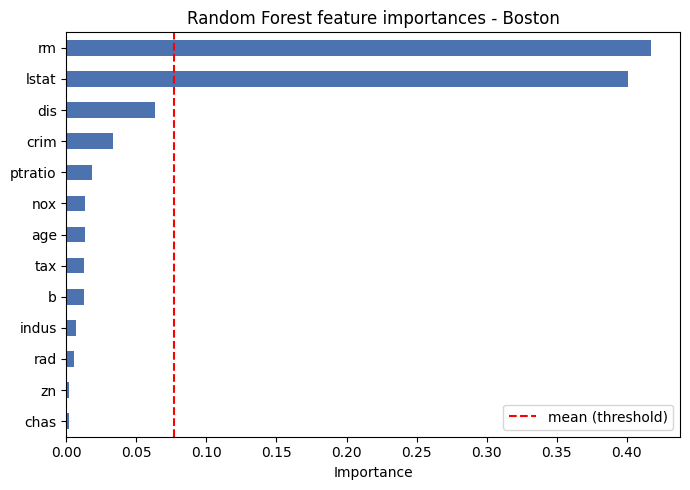

In [18]:
importances = pd.Series(sfm.estimator_.feature_importances_, index=X_boston.columns).sort_values()

plt.figure(figsize=(7, 5))
importances.plot(kind='barh', color='#4c72b0')
plt.axvline(importances.mean(), color='red', linestyle='--', label='mean (threshold)')
plt.xlabel('Importance')
plt.title('Random Forest feature importances - Boston')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
summary = pd.DataFrame({
    'Iris features': iris_results.set_index('Method')['Num Features'],
    'Iris accuracy': iris_results.set_index('Method')['Accuracy'],
    'Boston features': boston_results.set_index('Method')['Num Features'],
    'Boston MSE': boston_results.set_index('Method')['MSE'],
    'Boston R2': boston_results.set_index('Method')['R2']
})
summary.round(4)

,Iris features,Iris accuracy,Boston features,Boston MSE,Boston R2
Method,,,,,
All features,4,0.9111,13,21.5174,0.7112
SelectKBest,2,0.9111,6,25.9834,0.6513
RFE,2,0.9111,6,23.2131,0.6885
Tree-based,2,0.9111,2,29.8163,0.5999


## Observations

**Iris:** the petal length and petal width features are much more informative than the sepal features (their F-scores are far higher), and SelectKBest and the tree-based method both pick the two petal features. With just these 2 features the Logistic Regression does about as well as with all 4, so half the features can be dropped with little or no loss in accuracy. This makes sense since the species are separated mostly by petal size.

**Boston:** lstat (% lower status population) and rm (average number of rooms) are the strongest features and every method keeps them. The tree-based method usually keeps only a few features (those above the mean importance), while SelectKBest and RFE keep 6. Using fewer features gives a slightly higher MSE than the full 13 feature model, but most of the predictive power is kept with less than half the features. RFE tends to do better than SelectKBest here because it looks at the features together with the model instead of scoring each one on its own.

## Conclusion

In this experiment three feature selection approaches - a filter method (SelectKBest), a wrapper method (RFE) and an embedded method (tree-based SelectFromModel) - were applied to a classification task (Iris) and a regression task (Boston Housing). In both cases a large number of features could be removed while keeping the model performance close to the model trained on all features.

The filter method is the fastest but ignores interactions between features, RFE takes the model into account and usually gives the best subset for a fixed number of features, and the tree-based method decides the number of features on its own based on importance. Feature selection reduces model complexity, training time and the risk of overfitting, and also makes the model easier to interpret by showing which features actually matter.